In [3]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd


In [4]:
df = pd.read_csv("../DataSet/clean_iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## predictive KNN

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# split the data into features and target variable
x = df.drop('species', axis=1)
y = df['species']

# split the data into training and testing sets, with 80% of the data used for training and 20% for testing
x_train, x_test, y_train, y_test = train_test_split(x, y, 
test_size=0.2, random_state=42, stratify=y)

# use the standard scaler to scale the features to 
# prevent bias in the model due to different scales of the features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# create a KNN classifier and have it look at the 7 nearest neighbors to make a prediction
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train_scaled, y_train)

y_pred = knn.predict(x_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667
Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.91      1.00      0.95        10
 Iris-virginica       1.00      0.90      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [21]:
new_flowers = pd.DataFrame(
    [
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.5, 3.0, 5.8, 2.2],
    ],
    columns=x.columns
)

new_flowers_scaled = scaler.transform(new_flowers)
new_flowers["Predicted species"] = knn.predict(new_flowers_scaled)

print(new_flowers)

   sepal_length  sepal_width  petal_length  petal_width Predicted species
0           5.1          3.5           1.4          0.2       Iris-setosa
1           6.0          2.9           4.5          1.5   Iris-versicolor
2           6.5          3.0           5.8          2.2    Iris-virginica


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

y_pred = knn.predict(X_test)

# Count correct vs total
correct = (np.array(y_test) == np.array(y_pred)).sum()
print(f"{correct} correct out of {len(y_test)}")   # 29 out of 30

# Show ONLY the flowers it got wrong with their measurements
check = X_test.copy()
check["actual"] = np.array(y_test)
check["predicted"] = y_pred
check["correct"] = check["actual"] == check["predicted"]
print(check[~check["correct"]])

# Confusion matrix shows WHERE the errors land
print(confusion_matrix(y_test, y_pred))

29 correct out of 30
     sepal_length  sepal_width  petal_length  petal_width          actual  \
136           6.0          3.0           4.8          1.8  Iris-virginica   

           predicted  correct  
136  Iris-versicolor    False  
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


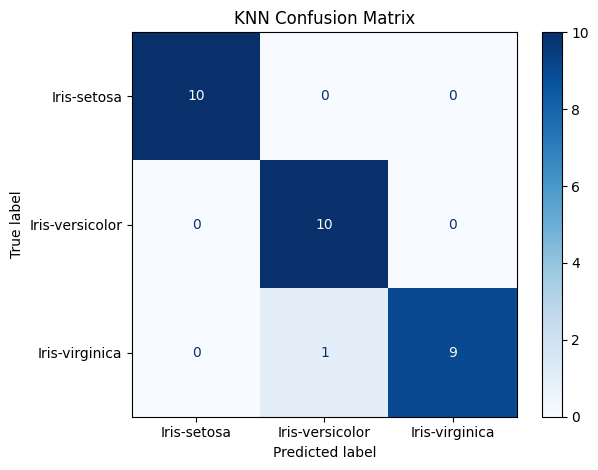

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# get the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=knn.classes_)

# gets the confusion matrix and displays it in a nice format
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn.classes_
)
# nice colors
display.plot(cmap="Blues", values_format="d")

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

## Visualizing the KNN

**Decision regions:** where the 7-nearest-neighbor vote picks each species, using petals only so it can be drawn in 2D. Red rings mark flowers your 4-feature model gets wrong; dashed rings mark flowers this petals-only view gets wrong.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# --- KNN decision regions ---
# KNN has no formula to plot, so we show what it *does*: for every point on a grid,
# ask "which species are your 7 nearest neighbors?" and color the region by the answer.
# We can only draw 2 dimensions, so this picture uses a petals-only KNN.
# Your real model uses all 4 features, so the two can disagree on borderline flowers.

features_2d = ["petal_length", "petal_width"]
scaler_2d = StandardScaler()
x_train_2d = scaler_2d.fit_transform(x_train[features_2d])
knn_2d = KNeighborsClassifier(n_neighbors=7).fit(x_train_2d, y_train)

species = list(knn.classes_)
colors = {"Iris-setosa": "#2a78d6", "Iris-versicolor": "#eb6834", "Iris-virginica": "#1baf7a"}
markers = {"Iris-setosa": "o", "Iris-versicolor": "s", "Iris-virginica": "^"}

# grid covering the data (in cm, so the axes are readable)
pl = np.linspace(x[features_2d[0]].min() - 0.5, x[features_2d[0]].max() + 0.5, 400)
pw = np.linspace(x[features_2d[1]].min() - 0.3, x[features_2d[1]].max() + 0.3, 400)
gl, gw = np.meshgrid(pl, pw)
grid = pd.DataFrame({features_2d[0]: gl.ravel(), features_2d[1]: gw.ravel()})
zone = knn_2d.predict(scaler_2d.transform(grid))
zone_idx = np.array([species.index(s) for s in zone]).reshape(gl.shape)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.contourf(gl, gw, zone_idx, levels=[-0.5, 0.5, 1.5, 2.5],
            cmap=ListedColormap([colors[s] for s in species]), alpha=0.15)
ax.contour(gl, gw, zone_idx, levels=[0.5, 1.5], colors="#888888", linewidths=1)

for s in species:
    tr = x_train[y_train == s]
    ax.scatter(tr[features_2d[0]], tr[features_2d[1]], c=colors[s], marker=markers[s],
               s=40, alpha=0.45, edgecolors="white", linewidths=0.8)
    te = x_test[y_test == s]
    ax.scatter(te[features_2d[0]], te[features_2d[1]], c=colors[s], marker=markers[s],
               s=80, edgecolors="black", linewidths=1.2)

# mark test flowers each model gets wrong
actual = np.array(y_test)
wrong_4d = x_test[actual != knn.predict(x_test_scaled)]
wrong_2d = x_test[actual != knn_2d.predict(scaler_2d.transform(x_test[features_2d]))]
ax.scatter(wrong_4d[features_2d[0]], wrong_4d[features_2d[1]], s=380, facecolors="none",
           edgecolors="#d03b3b", linewidths=2)
ax.scatter(wrong_2d[features_2d[0]], wrong_2d[features_2d[1]], s=260, facecolors="none",
           edgecolors="black", linewidths=1.5, linestyle="--")

handles = [Line2D([], [], marker=markers[s], color=colors[s], linestyle="", markersize=9,
                  label=s.replace("Iris-", "")) for s in species]
handles += [
    Line2D([], [], marker="o", color="#bbbbbb", linestyle="", markersize=6, alpha=0.6, label="train flower"),
    Line2D([], [], marker="o", color="#bbbbbb", markeredgecolor="black", linestyle="", markersize=9, label="test flower"),
    Line2D([], [], marker="o", markerfacecolor="none", markeredgecolor="#d03b3b", markeredgewidth=2,
           linestyle="", markersize=14, label=f"wrong: your 4-feature model ({len(wrong_4d)})"),
    Line2D([], [], marker="o", markerfacecolor="none", markeredgecolor="black", markeredgewidth=1.5,
           linestyle="", markersize=12, label=f"wrong: this petals-only view ({len(wrong_2d)})"),
]
ax.legend(handles=handles, loc="upper left", frameon=False)
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("KNN (k=7) decision regions - petals only", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig("knn_decision_regions.png", dpi=150, bbox_inches="tight")
plt.show()


**Test accuracy vs. k:** each dot is a separate 4-feature KNN with a different number of neighbors, scored on the 30 test flowers (one flower is about 3.3%).

In [ ]:
# --- Test accuracy vs. k (full 4-feature model) ---
# Each dot is a separate KNN model trained with a different number of neighbors (k),
# scored on the same 30 test flowers. One flower = about 3.3% accuracy.
ks = range(1, 31)
acc = [accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k)
                      .fit(x_train_scaled, y_train).predict(x_test_scaled)) for k in ks]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ks, acc, color="#2a78d6", linewidth=2, marker="o", markersize=5)
ax.scatter([7], [acc[6]], s=120, color="#2a78d6", edgecolors="white", linewidths=2, zorder=3)
ax.annotate(f"k=7 (our model): {acc[6]:.1%}", (7, acc[6]), xytext=(10, -25),
            textcoords="offset points", fontsize=9)
ax.set_xlabel("k (number of neighbors)")
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy vs. k - all 4 features", loc="left")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(min(acc) - 0.03, 1.01)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("knn_accuracy_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()
